In [11]:
import numpy as np
import os
import json
from pathlib import Path
import matplotlib.pyplot as plt

In [12]:
def get_result_and_meta(file_path: str):
    with np.load(file_path, allow_pickle=True) as f:
        result = f['data']
        meta_bytes = f['metadata'].tobytes()
        meta_data = json.loads(meta_bytes.decode('utf-8'))
    
    return (result, meta_data)

def load_results(root_dir: str):
    root_dir = Path(root_dir)

    if not root_dir.exists():
        print("No results")
        return None

    results = []
    for i, item in enumerate(root_dir.iterdir()):
        if item.is_file():
            result, meta_data = get_result_and_meta(item.resolve())
            results.append((result, meta_data))

            print(i, end=':\t')
            print(item.name, meta_data, sep='\n\t', end='\n\n')
    
    return results

# 2. Анализ

In [13]:
def to_latex(text):
    return r"$" + text + r"$"

In [14]:
idx2param = {
    0: "sigma",
    1: "rho",
    2: "beta"
}

idx2var = {
    0: 'x',
    1: 'y',
    2: 'z',
}

param2idx = {v: k for k, v in idx2param.items()}
var2idx = {v: k for k, v in idx2var.items()}

# 2.0. Бифуркационная диаграмма 1D по временному шагу

In [15]:
def get_results_bifurcation1D_dt(results, record_time, transient_time, h_range, N, state_var):
    for (result, data) in results:
        ok = [False] * 5
        
        ok[0] = abs(record_time - data['record_time']) < 1e-6
        ok[1] = abs(transient_time - data['transient_time']) < 1e-6
        ok[2] = abs(h_range[0] - data['h_range'][0]) < 1e-6 and \
                abs(h_range[1] - data['h_range'][1]) < 1e-6
        ok[3] = N == data['N']
        ok[4] = var2idx[state_var.lower()] == data['var_idx']
        
        if not (False in ok):
            return result, data
    
    print('Error: no such data in results')
    return None, None

In [82]:
results_dir = (Path(os.getcwd()) / 'results' / 'bifurcation1D_dt').resolve()
results_bifurcation1D_dt = load_results(results_dir)

0:	2025_12_23_03_21_13.npz
	{'record_time': 200, 'transient_time': 200, 'params': [10.0, 28.0, 2.6666666666666665], 'h_range': [0.001, 0.1], 'N': 250, 'var_idx': 0}



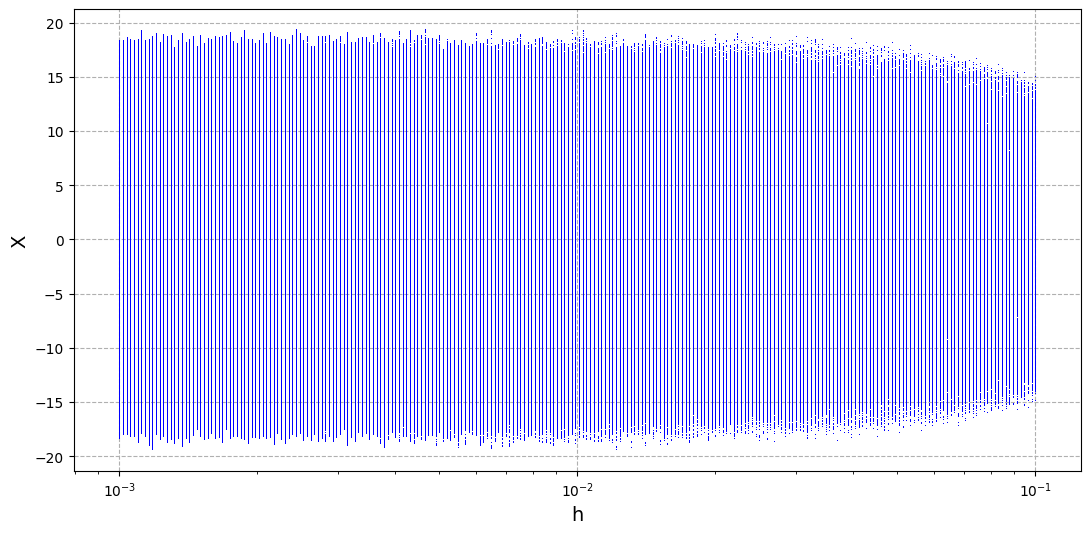

In [83]:
record_time = 200
transient_time = 200

h_range = (1e-3, 1e-1)
N = 250

state_var = "x"
# ================================================================================

result, data = get_results_bifurcation1D_dt(results_bifurcation1D_dt, record_time, transient_time, h_range, N, state_var)

if (result is not None) and (data is not None):

    h_values = np.logspace(np.log10(data['h_range'][0]), np.log10(data['h_range'][1]), num=data['N'], base=10)
    var_values = result

    plt.figure(figsize=(13, 6))

    for i in range(data['N']):
        # faster
        plt.plot([h_values[i]] * var_values[i].shape[0], var_values[i], ',b') # pixels with blue color 

    plt.xlabel('h', fontsize=14)
    plt.ylabel(idx2var[data['var_idx']].upper(), fontsize=14)
    #plt.xlim(data['h_range'][0], data['h_range'][1])
    plt.xscale('log')
    plt.grid(True, linestyle='--')
    plt.show()

## 2.1. Бифуркационная диаграмма 1D

In [5]:
results_bifurcation1D = []

In [6]:
def get_results_bifurcation1D(record_time, transient_time, h, param, param_range, N, state_var):
    for (result, data) in results_bifurcation1D:
        ok = [False] * 7
        
        ok[0] = abs(record_time - data['record_time']) < 1e-6
        ok[1] = abs(transient_time - data['transient_time']) < 1e-6
        ok[2] = abs(h - data['h']) < 1e-6
        ok[3] = param2idx[param] == data['param_idx']
        ok[4] = abs(param_range[0] - data['param_range'][0]) < 1e-6 and \
                abs(param_range[1] - data['param_range'][1]) < 1e-6
        ok[5] = N == data['N']
        ok[6] = var2idx[state_var.lower()] == data['var_idx']
        
        if not (False in ok):
            return result, data
    
    print('Error: no such data in results')
    return None, None

In [7]:
results_dir = (Path(os.getcwd()) / 'results' / 'bifurcation1D').resolve()
results_bifurcation1D = load_results(results_dir)

0:	2025_12_09_12_14_13.npz
	{'record_time': 200, 'transient_time': 200, 'h': 0.01, 'param_idx': 1, 'param_range': [0.0, 240.0], 'N': 1000, 'var_idx': 0}

1:	2025_12_09_12_59_03.npz
	{'record_time': 200, 'transient_time': 200, 'h': 0.01, 'param_idx': 1, 'param_range': [0.0, 250.0], 'N': 1000, 'var_idx': 0}

2:	2025_12_09_14_54_56.npz
	{'record_time': 200, 'transient_time': 200, 'h': 0.01, 'param_idx': 0, 'param_range': [5.0, 20.0], 'N': 1000, 'var_idx': 0}

3:	2025_12_09_14_57_05.npz
	{'record_time': 200, 'transient_time': 200, 'h': 0.01, 'param_idx': 2, 'param_range': [0.0, 4.0], 'N': 1000, 'var_idx': 0}



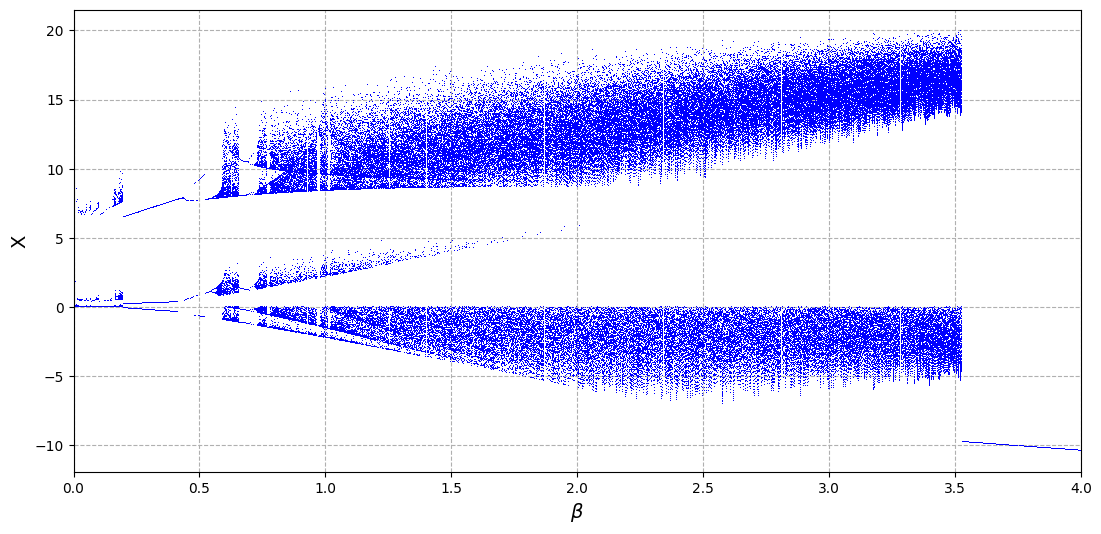

In [87]:
record_time = 200
transient_time = 200
h = 0.01

param = "beta"
state_var = "x"

param_range = (0.0, 4.0)
N = 1000

# ================================================================================

result, data = get_results_bifurcation1D(record_time, transient_time, h, param, param_range, N, state_var)

if (result is not None) and (data is not None):

    param_values = np.linspace(data['param_range'][0], data['param_range'][1], data['N'])
    var_values = result

    plt.figure(figsize=(13, 6))

    for i in range(data['N']):
        # faster
        plt.plot([param_values[i]] * var_values[i].shape[0], var_values[i], ',b') # pixels with blue color 
        # slower
        #plt.scatter([param_values[i]] * var_values[i].shape[0], var_values[i], color='b', s=0.1)

    plt.xlabel(to_latex("\\" + idx2param[data['param_idx']]), fontsize=14)
    plt.ylabel(idx2var[data['var_idx']].upper(), fontsize=14)
    plt.xlim(data['param_range'][0], data['param_range'][1])
    plt.xticks(np.arange(data['param_range'][0], data['param_range'][1] + 1e-3, 0.5))
    plt.grid(True, linestyle='--')
    plt.show()

## 2.2. Бифуркационная диаграмма 2D

In [51]:
results_bifurcation2D = []

In [52]:
def get_results_bifurcation2D(record_time, transient_time, h, params_pair, param1_range, param2_range, N, state_var):
    for (result, data) in results_bifurcation2D:
        ok = [False] * 9
        
        ok[0] = abs(record_time - data['record_time']) < 1e-6
        ok[1] = abs(transient_time - data['transient_time']) < 1e-6
        ok[2] = abs(h - data['h']) < 1e-6
        ok[3] = param2idx[params_pair[0]] == data['param_idxs'][0]
        ok[4] = param2idx[params_pair[1]] == data['param_idxs'][1]
        ok[5] = abs(param1_range[0] - data['param1_range'][0]) < 1e-6 and \
                abs(param1_range[1] - data['param1_range'][1]) < 1e-6
        ok[6] = abs(param2_range[0] - data['param2_range'][0]) < 1e-6 and \
                abs(param2_range[1] - data['param2_range'][1]) < 1e-6
        ok[7] = N == data['N']
        ok[8] = var2idx[state_var.lower()] == data['var_idx']
        
        if not (False in ok):
            return result, data
    
    print('Error: no such data in results')
    return None, None

In [8]:
results_dir = (Path(os.getcwd()) / 'results' / 'bifurcation2D').resolve()
results_bifurcation2D = load_results(results_dir)

0:	2025_12_09_11_43_47.npz
	{'record_time': 200, 'transient_time': 200, 'h': 0.01, 'param_idxs': [0, 1], 'param1_range': [0.0, 100.0], 'param2_range': [20.0, 100.0], 'N': 500, 'var_idx': 0}

1:	2025_12_09_12_24_52.npz
	{'record_time': 200, 'transient_time': 200, 'h': 0.01, 'param_idxs': [0, 1], 'param1_range': [5.0, 20.0], 'param2_range': [0.0, 220.0], 'N': 500, 'var_idx': 0}

2:	2025_12_09_14_10_40.npz
	{'record_time': 200, 'transient_time': 200, 'h': 0.01, 'param_idxs': [0, 2], 'param1_range': [0.0, 40.0], 'param2_range': [0.0, 4.0], 'N': 500, 'var_idx': 0}

3:	2025_12_09_14_25_14.npz
	{'record_time': 200, 'transient_time': 200, 'h': 0.01, 'param_idxs': [1, 2], 'param1_range': [0.0, 400.0], 'param2_range': [0.0, 10.0], 'N': 500, 'var_idx': 0}



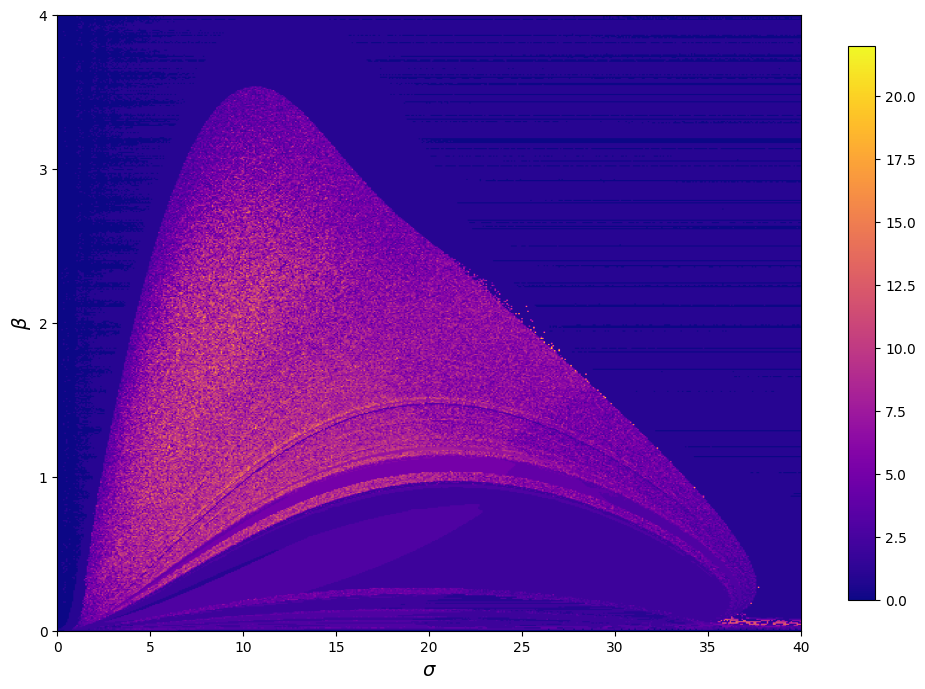

In [71]:
record_time = 200
transient_time = 200
h = 0.01

param1 = "sigma"
param2 = "beta"
state_var = "x"

param1_range = (0.0, 40.0)
param2_range = (0.0, 4.0)
N = 500

# ================================================================================

result, data = get_results_bifurcation2D(record_time, transient_time, h, (param1, param2), param1_range, param2_range, N, state_var)

if (result is not None) and (data is not None):
    param1_values = np.linspace(data['param1_range'][0], data['param1_range'][1], data['N'])
    param2_values = np.linspace(data['param2_range'][0], data['param2_range'][1], data['N'])

    result_grid = result.reshape((data['N'], data['N'])).T

    fig, ax = plt.subplots(figsize=(12, 8))

    img = ax.imshow(result_grid, 
                    cmap='plasma', origin='lower', aspect='auto', 
                    extent=(data['param1_range'][0], data['param1_range'][1], data['param2_range'][0], data['param2_range'][1])
                    )
    fig.colorbar(img, ax=ax, shrink=0.9)

    ax.set_xlabel(to_latex("\\" + idx2param[data['param_idxs'][0]]), fontsize=14)
    ax.set_ylabel(to_latex("\\" + idx2param[data['param_idxs'][1]]), fontsize=14)

    ax.set_xticks(np.arange(data['param1_range'][0], data['param1_range'][1] + 1e-3, 5))
    ax.set_yticks(np.arange(data['param2_range'][0], data['param2_range'][1] + 1e-3, 1))

    ax.set_xlim(data['param1_range'][0], data['param1_range'][1])
    ax.set_ylim(data['param2_range'][0], data['param2_range'][1])

    plt.show()